# Lab - EDA Bivariante: Amazon UK Product Insights Parte II

## Objetivo

Analizar datos de productos de Amazon UK para descubrir insights útiles sobre precios, categorías, valoraciones y productos best-seller.

Este notebook sigue un enfoque de trabajo propio de EDA bivariante:

1. Exploración inicial.
2. Limpieza básica.
3. Análisis categórico-categórico.
4. Análisis categórico-numérico.
5. Análisis numérico-numérico.
6. Tests estadísticos.
7. Visualizaciones.
8. Conclusiones orientadas a negocio.

# 1. Importar librerías

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency, pearsonr, spearmanr
from scipy import stats

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

# 2. Cargar dataset

Coloca el archivo CSV en la misma carpeta que este notebook.

Nombre esperado:

`amz_uk_price_prediction_dataset.csv`

Si tu archivo se llama de otra forma, cambia la variable `file_path`.

In [2]:
file_path = "amz_uk_price_prediction_dataset.csv"

df = pd.read_csv(file_path)

df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


# 3. Exploración inicial

In [3]:
print("Shape:", df.shape)
df.info()

Shape: (2443651, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [4]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [5]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
uid,2443651.0,NaN,NaN,NaN,1370545.345231,816056.169852,1.0,658921.5,1349029.0,2060685.5,2828593.0
asin,2443651,2222742,B083L94P36,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,2443651,2077591,OYhmc Portable Pedal Exerc,723,NaN,NaN,NaN,NaN,NaN,NaN,NaN
stars,2443651.0,NaN,NaN,NaN,2.152836,2.194865,0.0,0.0,0.0,4.4,5.0
reviews,2443651.0,NaN,NaN,NaN,480.627757,5944.124151,0.0,0.0,0.0,59.0,1356658.0
price,2443651.0,NaN,NaN,NaN,89.243809,345.608862,0.0,9.99,19.09,45.99,100000.0
isBestSeller,2443651,2,False,2435671,NaN,NaN,NaN,NaN,NaN,NaN,NaN
boughtInLastMonth,2443651.0,NaN,NaN,NaN,25.896988,240.483727,0.0,0.0,0.0,0.0,50000.0
category,2443651,296,Sports & Outdoors,836265,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
df.isna().sum().sort_values(ascending=False)

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [7]:
print("Duplicados:", df.duplicated().sum())
print("Columnas:", df.columns.tolist())

Duplicados: 0
Columnas: ['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller', 'boughtInLastMonth', 'category']


## Interpretación inicial

En esta fase revisamos dimensiones, tipos de datos, nulos, duplicados y columnas disponibles.

Esto permite detectar problemas antes de realizar análisis estadísticos o visualizaciones.

# 4. Limpieza básica

In [8]:
df_clean = df.copy()

# Estandarizar nombres de columnas
df_clean.columns = df_clean.columns.str.strip()

# Eliminar duplicados exactos
df_clean = df_clean.drop_duplicates()

# Convertir variables clave a numéricas
df_clean["price"] = pd.to_numeric(df_clean["price"], errors="coerce")
df_clean["stars"] = pd.to_numeric(df_clean["stars"], errors="coerce")

if "reviews" in df_clean.columns:
    df_clean["reviews"] = pd.to_numeric(df_clean["reviews"], errors="coerce")

# Convertir isBestSeller a booleano
df_clean["isBestSeller"] = df_clean["isBestSeller"].astype(bool)

# Eliminar filas con nulos en variables clave
df_clean = df_clean.dropna(subset=["category", "price", "stars", "isBestSeller"])

df_clean.shape

(2443651, 9)

In [9]:
df_clean[["category", "price", "stars", "isBestSeller"]].isna().sum()

category        0
price           0
stars           0
isBestSeller    0
dtype: int64

# Parte 1 — Tendencias best-seller por categoría

## Objetivo

Entender la relación entre:

- `category`
- `isBestSeller`

Este es un análisis bivariante categórico-categórico.

## 1.1 Crosstab entre categoría y best-seller

In [10]:
category_bestseller_crosstab = pd.crosstab(
    df_clean["category"],
    df_clean["isBestSeller"]
)

category_bestseller_crosstab.head()

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3


## 1.2 Proporción de best-sellers por categoría

In [11]:
category_bestseller_prop = pd.crosstab(
    df_clean["category"],
    df_clean["isBestSeller"],
    normalize="index"
)

bestseller_rates = (
    category_bestseller_prop[True]
    .sort_values(ascending=False)
    .reset_index()
)

bestseller_rates.columns = ["category", "bestseller_rate"]

bestseller_rates.head(20)

,category,bestseller_rate
0,Grocery,0.058135
1,Smart Home Security & Lighting,0.057692
2,Health & Personal Care,0.057686
3,Mobile Phone Accessories,0.042471
4,Power & Hand Tools,0.035339
5,"Billiard, Snooker & Pool",0.032129
6,Pet Supplies,0.030200
7,Home Brewing & Wine Making,0.028455
8,Wind Instruments,0.028000
9,Mirrors,0.028000


### Interpretación

Las categorías con mayor proporción de productos best-seller pueden indicar áreas con mayor concentración de demanda o preferencias de compra más claras.

Es importante revisar también el volumen de productos por categoría, porque una categoría pequeña puede mostrar una proporción alta con pocos productos.

## 1.3 Test Chi-cuadrado

In [12]:
chi2, p_value, dof, expected = chi2_contingency(category_bestseller_crosstab)

print("Estadístico Chi-cuadrado:", chi2)
print("P-value:", p_value)
print("Grados de libertad:", dof)

if p_value < 0.05:
    print("Rechazamos H0: la categoría y el estado best-seller están asociados.")
else:
    print("No rechazamos H0: no se detecta asociación significativa.")

Estadístico Chi-cuadrado: 36540.20270061387
P-value: 0.0
Grados de libertad: 295
Rechazamos H0: la categoría y el estado best-seller están asociados.


### Hipótesis

- **H0**: La categoría y el estado best-seller son independientes.
- **H1**: La categoría y el estado best-seller están asociados.

Si el `p-value` es menor que 0.05, rechazamos H0.

## 1.4 V de Cramér

In [13]:
def cramers_v(confusion_matrix):
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    r, k = confusion_matrix.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

cramers_v_value = cramers_v(category_bestseller_crosstab)

print("V de Cramér:", cramers_v_value)

V de Cramér: 0.1222829439760564


### Interpretación

La V de Cramér mide la fuerza de la asociación:

- Cerca de 0: asociación débil o inexistente.
- Alrededor de 0.1: asociación débil.
- Alrededor de 0.3: asociación moderada.
- 0.5 o más: asociación fuerte.

Es importante porque en datasets grandes un test Chi-cuadrado puede ser significativo aunque la asociación práctica sea débil.

## 1.5 Gráfico de barras apiladas

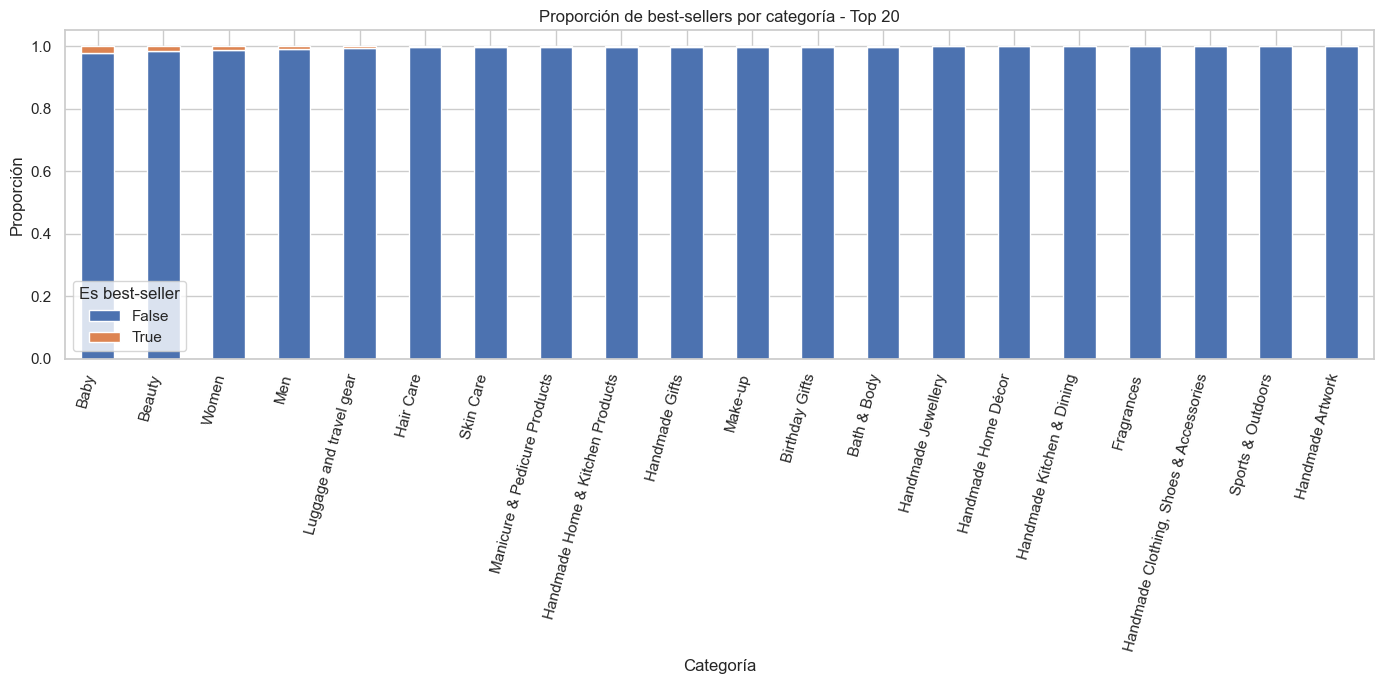

In [14]:
top_20_categories = df_clean["category"].value_counts().head(20).index

top_20_data = df_clean[df_clean["category"].isin(top_20_categories)]

stacked_data = pd.crosstab(
    top_20_data["category"],
    top_20_data["isBestSeller"],
    normalize="index"
).sort_values(by=True, ascending=False)

stacked_data.plot(
    kind="bar",
    stacked=True,
    figsize=(14, 7)
)

plt.title("Proporción de best-sellers por categoría - Top 20")
plt.xlabel("Categoría")
plt.ylabel("Proporción")
plt.xticks(rotation=75, ha="right")
plt.legend(title="Es best-seller")
plt.tight_layout()
plt.show()

# Parte 2 — Precios y valoraciones por categorías

## Objetivo

Analizar cómo varían precios y ratings según la categoría.

Antes del análisis se eliminan outliers de precio con el método IQR.

## 2.0 Eliminar outliers de precio con IQR

In [15]:
Q1 = df_clean["price"].quantile(0.25)
Q3 = df_clean["price"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_no_outliers = df_clean[
    (df_clean["price"] >= lower_bound) &
    (df_clean["price"] <= upper_bound)
].copy()

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Límite inferior:", lower_bound)
print("Límite superior:", upper_bound)
print("Shape original:", df_clean.shape)
print("Shape sin outliers:", df_no_outliers.shape)
print("Filas eliminadas:", df_clean.shape[0] - df_no_outliers.shape[0])

Q1: 9.99
Q3: 45.99
IQR: 36.0
Límite inferior: -44.01
Límite superior: 99.99000000000001
Shape original: (2443651, 9)
Shape sin outliers: (2115963, 9)
Filas eliminadas: 327688


### Interpretación

El método IQR elimina precios extremadamente bajos o altos.

Esto evita que los outliers distorsionen medias, gráficos y correlaciones.

## 2.1 Violin plot de precios por categoría — Top 20

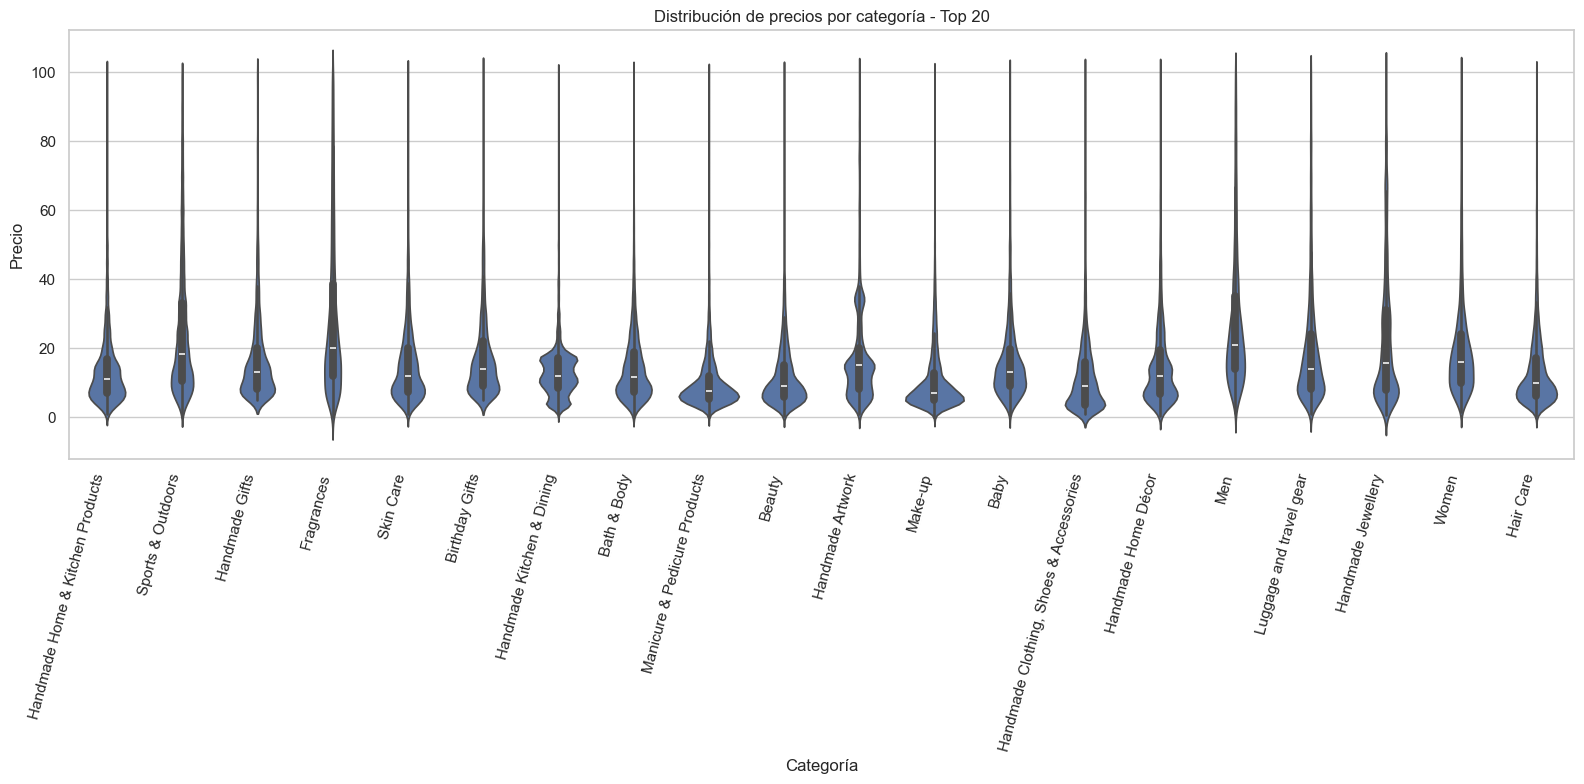

In [16]:
top_20_categories_no_outliers = (
    df_no_outliers["category"]
    .value_counts()
    .head(20)
    .index
)

violin_data = df_no_outliers[
    df_no_outliers["category"].isin(top_20_categories_no_outliers)
]

plt.figure(figsize=(16, 8))

sns.violinplot(
    data=violin_data,
    x="category",
    y="price"
)

plt.title("Distribución de precios por categoría - Top 20")
plt.xlabel("Categoría")
plt.ylabel("Precio")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

## 2.2 Categoría con mayor mediana de precio

In [17]:
median_price_by_category = (
    df_no_outliers
    .groupby("category")["price"]
    .median()
    .sort_values(ascending=False)
    .reset_index()
)

median_price_by_category.head(20)

,category,price
0,Desktop PCs,74.000
1,Boxing Shoes,69.790
2,Tablets,69.000
3,Graphics Cards,68.540
4,Motherboards,67.920
5,Made in Italy Handmade,64.000
6,Digital Frames,63.900
7,Streaming Clients,62.680
8,Golf Shoes,62.390
9,Ski Helmets,61.330


In [18]:
highest_median_price_category = median_price_by_category.iloc[0]

print("Categoría con mayor mediana de precio:")
print(highest_median_price_category)

Categoría con mayor mediana de precio:
category    Desktop PCs
price              74.0
Name: 0, dtype: object


### Interpretación

La mediana es robusta frente a valores extremos y suele ser más adecuada que la media para analizar precios.

## 2.3 Bar chart del precio medio — Top 10 categorías por volumen

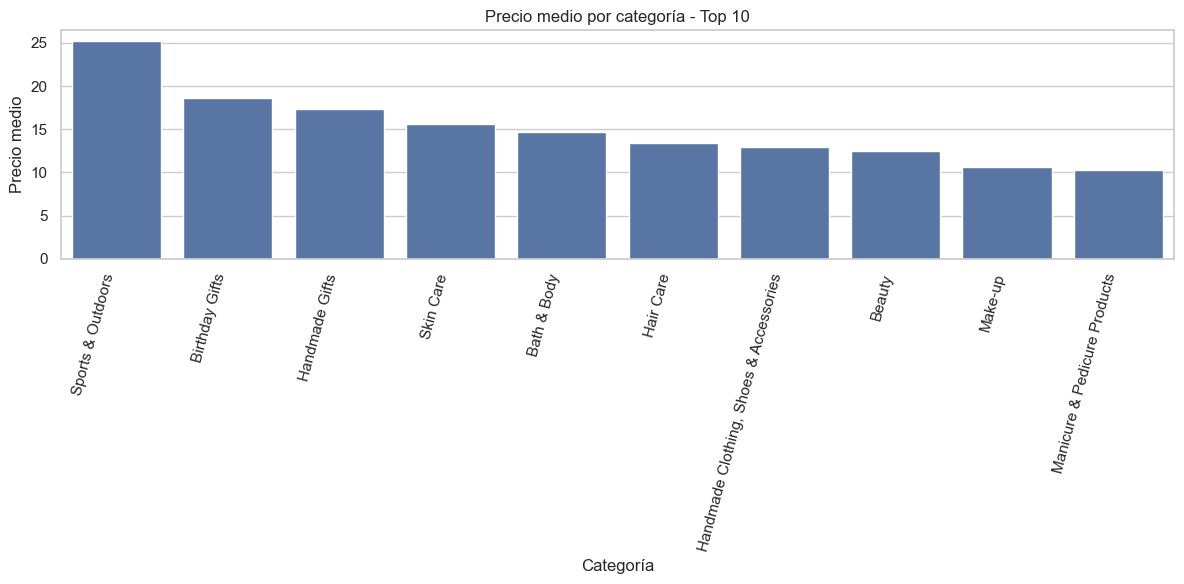

,category,price
0,Sports & Outdoors,25.172065
1,Birthday Gifts,18.600195
2,Handmade Gifts,17.395112
3,Skin Care,15.654722
4,Bath & Body,14.678683
5,Hair Care,13.461408
6,"Handmade Clothing, Shoes & Accessories",12.958639
7,Beauty,12.523480
8,Make-up,10.612918
9,Manicure & Pedicure Products,10.231825


In [19]:
top_10_categories_no_outliers = (
    df_no_outliers["category"]
    .value_counts()
    .head(10)
    .index
)

avg_price_top_10 = (
    df_no_outliers[df_no_outliers["category"].isin(top_10_categories_no_outliers)]
    .groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=avg_price_top_10,
    x="category",
    y="price"
)

plt.title("Precio medio por categoría - Top 10")
plt.xlabel("Categoría")
plt.ylabel("Precio medio")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

avg_price_top_10

## 2.4 Categoría con mayor precio medio

In [20]:
avg_price_by_category = (
    df_no_outliers
    .groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

avg_price_by_category.head(20)

,category,price
0,Motherboards,68.772432
1,Boxing Shoes,67.417803
2,Desktop PCs,66.915562
3,Tablets,66.552971
4,Graphics Cards,65.103509
5,Digital Frames,60.745129
6,Streaming Clients,60.241803
7,Hockey Shoes,60.094796
8,Computer Cases,58.339884
9,Skiing Poles,57.867770


In [21]:
highest_avg_price_category = avg_price_by_category.iloc[0]

print("Categoría con mayor precio medio:")
print(highest_avg_price_category)

Categoría con mayor precio medio:
category    Motherboards
price          68.772432
Name: 0, dtype: object


## 2.5 Box plot de ratings — Top 10 categorías

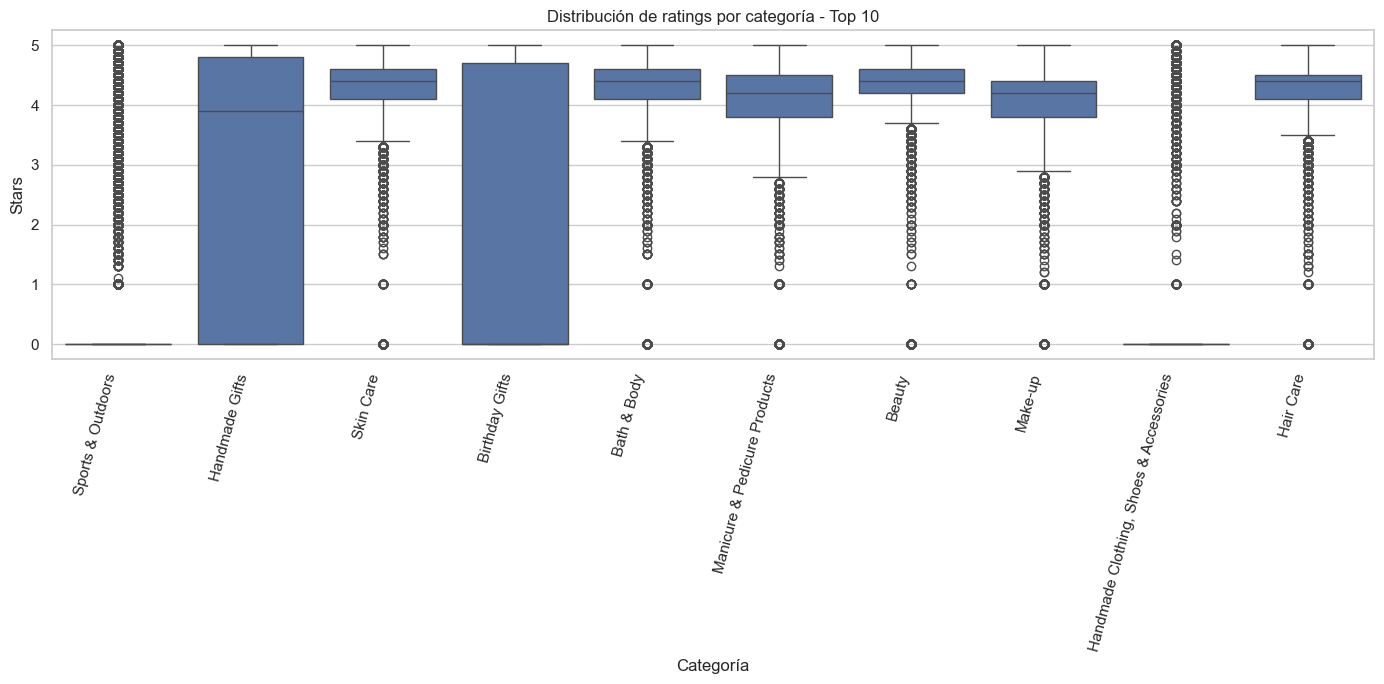

In [22]:
top_10_categories_ratings = (
    df_no_outliers["category"]
    .value_counts()
    .head(10)
    .index
)

ratings_box_data = df_no_outliers[
    df_no_outliers["category"].isin(top_10_categories_ratings)
]

plt.figure(figsize=(14, 7))

sns.boxplot(
    data=ratings_box_data,
    x="category",
    y="stars"
)

plt.title("Distribución de ratings por categoría - Top 10")
plt.xlabel("Categoría")
plt.ylabel("Stars")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

## 2.6 Categoría con mayor mediana de rating

In [23]:
median_rating_by_category = (
    df_no_outliers
    .groupby("category")["stars"]
    .median()
    .sort_values(ascending=False)
    .reset_index()
)

median_rating_by_category.head(20)

,category,stars
0,Computer Memory,4.7
1,Building & Construction Toys,4.6
2,Office Paper Products,4.6
3,Luxury Food & Drink,4.6
4,Kids' Play Figures,4.6
5,Hobbies,4.6
6,"Beer, Wine & Spirits",4.6
7,Laptop Accessories,4.6
8,Cables & Accessories,4.5
9,CPUs,4.5


In [24]:
highest_median_rating_category = median_rating_by_category.iloc[0]

print("Categoría con mayor mediana de rating:")
print(highest_median_rating_category)

Categoría con mayor mediana de rating:
category    Computer Memory
stars                   4.7
Name: 0, dtype: object


# Parte 3 — Relación entre precio y rating

## Objetivo

Analizar si los productos más caros tienden a recibir mejores valoraciones.

Variables:

- `price`
- `stars`

## 3.1 Correlación de Pearson

In [25]:
pearson_corr, pearson_p_value = pearsonr(
    df_no_outliers["price"],
    df_no_outliers["stars"]
)

print("Correlación de Pearson:", pearson_corr)
print("P-value:", pearson_p_value)

if pearson_p_value < 0.05:
    print("La correlación es estadísticamente significativa.")
else:
    print("La correlación no es estadísticamente significativa.")

Correlación de Pearson: -0.07767299878181345
P-value: 0.0
La correlación es estadísticamente significativa.


## 3.2 Correlación de Spearman

In [26]:
spearman_corr, spearman_p_value = spearmanr(
    df_no_outliers["price"],
    df_no_outliers["stars"]
)

print("Correlación de Spearman:", spearman_corr)
print("P-value:", spearman_p_value)

if spearman_p_value < 0.05:
    print("La correlación de Spearman es estadísticamente significativa.")
else:
    print("La correlación de Spearman no es estadísticamente significativa.")

Correlación de Spearman: -0.06679697280768324
P-value: 0.0
La correlación de Spearman es estadísticamente significativa.


### Interpretación

Pearson mide relación lineal.  
Spearman mide relación monotónica y es menos sensible a distribuciones no normales.

Una correlación significativa no implica necesariamente que la relación sea fuerte.

## 3.3 Scatter plot precio vs rating

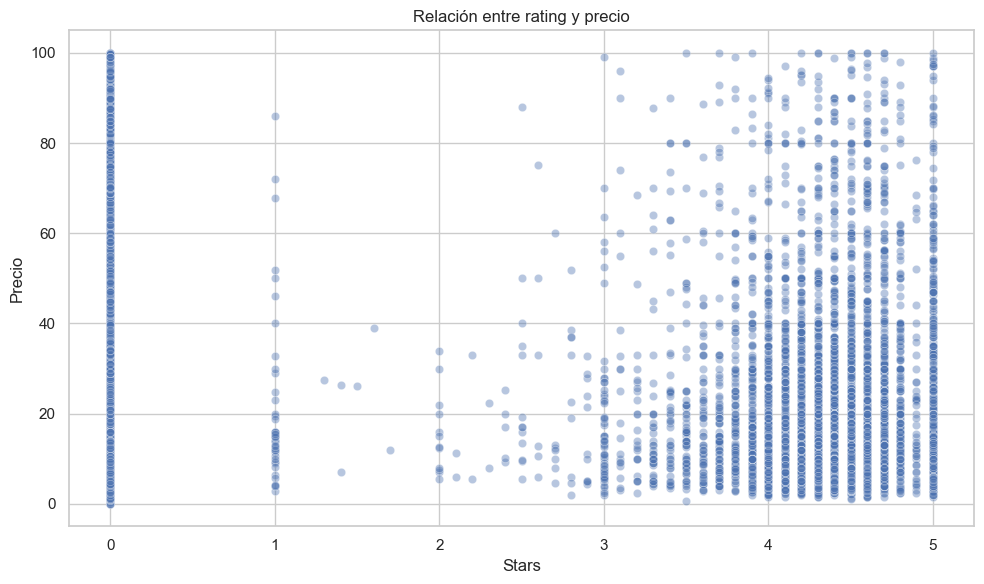

In [27]:
sample_df = df_no_outliers.sample(
    min(10000, len(df_no_outliers)),
    random_state=42
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=sample_df,
    x="stars",
    y="price",
    alpha=0.4
)

plt.title("Relación entre rating y precio")
plt.xlabel("Stars")
plt.ylabel("Precio")
plt.tight_layout()
plt.show()

### Interpretación

El scatter plot permite comprobar si existe un patrón visual claro entre rating y precio.

En e-commerce, un precio mayor no implica necesariamente una mejor valoración.

## 3.4 Heatmap de correlaciones

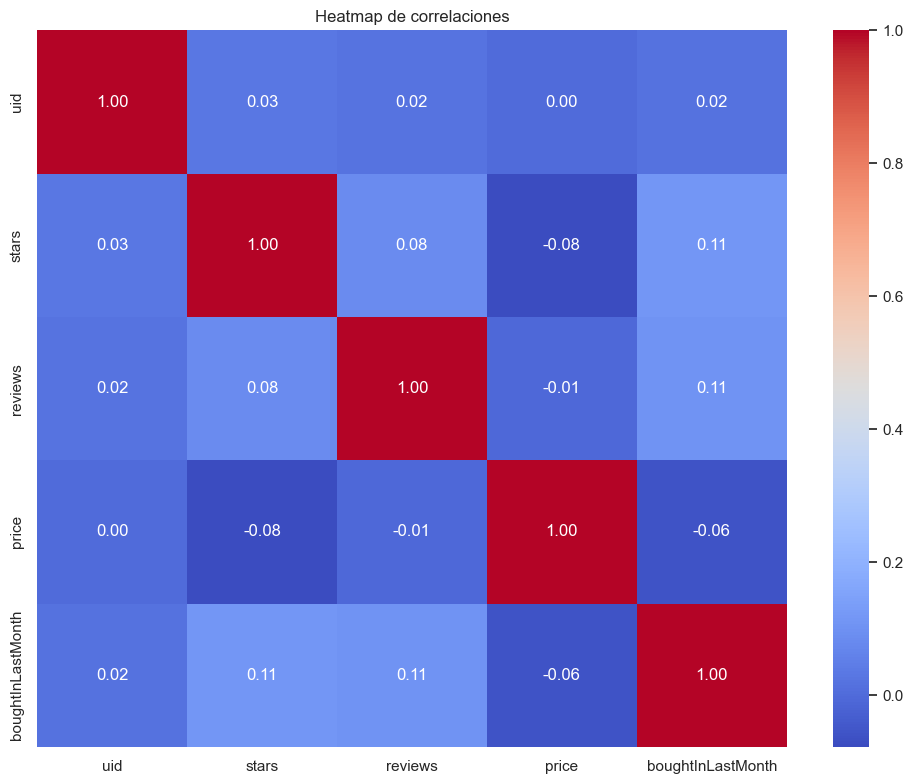

In [28]:
numeric_df = df_no_outliers.select_dtypes(include=np.number)

corr_matrix = numeric_df.corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Heatmap de correlaciones")
plt.tight_layout()
plt.show()

## 3.5 QQ plot de precios

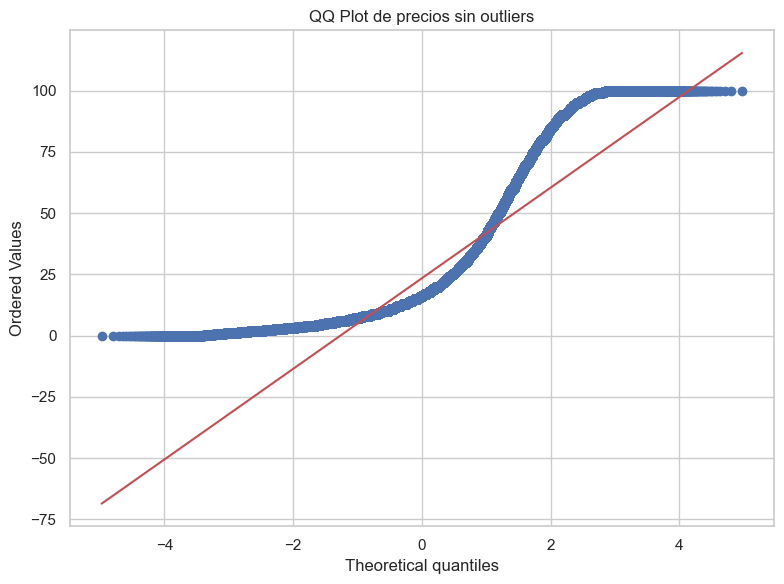

In [29]:
plt.figure(figsize=(8, 6))

stats.probplot(df_no_outliers["price"], dist="norm", plot=plt)

plt.title("QQ Plot de precios sin outliers")
plt.tight_layout()
plt.show()

### Interpretación

El QQ plot ayuda a evaluar si los precios siguen una distribución normal.

En precios de productos es habitual encontrar distribuciones asimétricas, incluso tras eliminar outliers.

# Bonus — Análisis sin eliminar outliers

## Bonus 1 — Distribución de precios con outliers

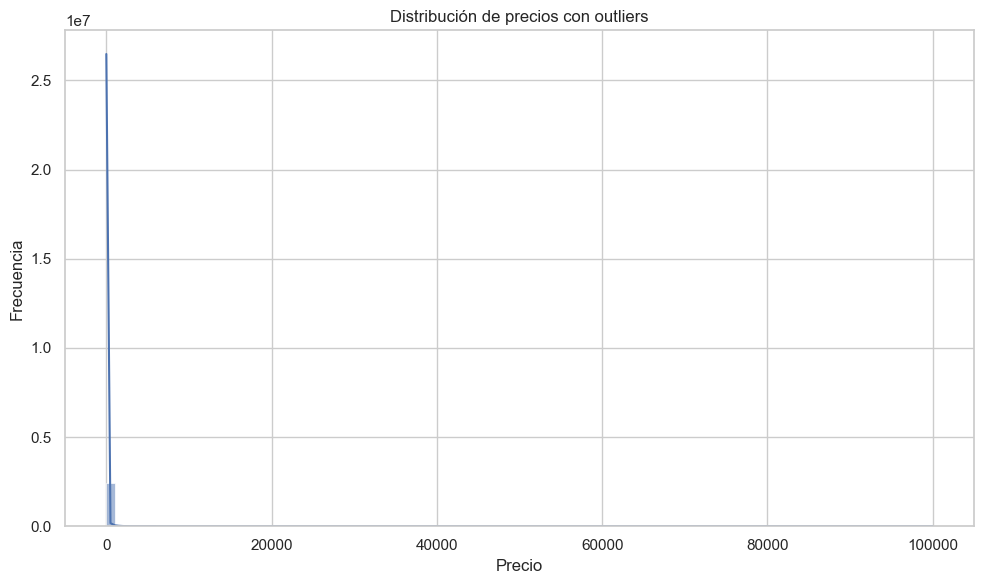

In [30]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df_clean["price"],
    bins=100,
    kde=True
)

plt.title("Distribución de precios con outliers")
plt.xlabel("Precio")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

## Bonus 2 — Precio medio por categoría con outliers

In [31]:
avg_price_with_outliers = (
    df_clean
    .groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

avg_price_with_outliers.head(20)

,category,price
0,Laptops,1087.987827
1,3D Printers,1018.036129
2,Desktop PCs,926.816064
3,Home Office Furniture,622.135898
4,Test & Measurement,559.382973
5,Home Audio Record Players,529.665585
6,CPUs,514.519317
7,Digital Cameras,496.156185
8,Material Handling Products,487.191813
9,Graphics Cards,444.746827


## Bonus 3 — Correlación con outliers

In [32]:
pearson_corr_outliers, pearson_p_value_outliers = pearsonr(
    df_clean["price"],
    df_clean["stars"]
)

spearman_corr_outliers, spearman_p_value_outliers = spearmanr(
    df_clean["price"],
    df_clean["stars"]
)

print("Pearson con outliers:", pearson_corr_outliers)
print("P-value Pearson:", pearson_p_value_outliers)
print("Spearman con outliers:", spearman_corr_outliers)
print("P-value Spearman:", spearman_p_value_outliers)

Pearson con outliers: -0.1249067326214852
P-value Pearson: 0.0
Spearman con outliers: -0.13316425462433998
P-value Spearman: 0.0


## Bonus 4 — Scatter plot con outliers

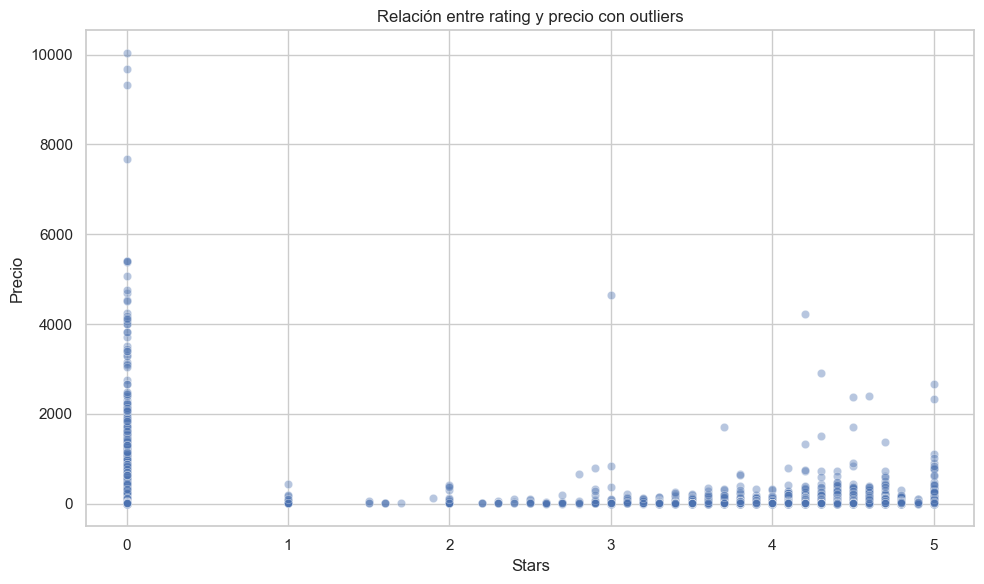

In [33]:
sample_df_outliers = df_clean.sample(
    min(10000, len(df_clean)),
    random_state=42
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=sample_df_outliers,
    x="stars",
    y="price",
    alpha=0.4
)

plt.title("Relación entre rating y precio con outliers")
plt.xlabel("Stars")
plt.ylabel("Precio")
plt.tight_layout()
plt.show()

## Insight del bonus

Mantener outliers puede ser útil para detectar productos premium o anomalías, pero distorsiona:

- Precios medios.
- Escalas de gráficos.
- Distribuciones.
- Correlaciones.

Por eso el análisis principal usa el dataframe sin outliers.

# Informe final orientado a negocio

## Principales hallazgos

1. **La categoría puede estar asociada con el estado best-seller.**  
   El test Chi-cuadrado permite comprobar si la distribución de best-sellers depende de la categoría.

2. **La V de Cramér mide la fuerza de la asociación.**  
   Es importante reportarla porque un p-value significativo no siempre implica una asociación fuerte.

3. **Los precios varían entre categorías.**  
   Los violin plots, medias y medianas ayudan a identificar categorías premium y categorías más económicas.

4. **La mediana es clave en análisis de precios.**  
   Al haber outliers, la mediana suele representar mejor el precio típico que la media.

5. **Precio y rating no tienen por qué estar fuertemente relacionados.**  
   Un producto más caro no necesariamente recibe mejores valoraciones.

6. **Los outliers cambian la interpretación.**  
   Por eso conviene comparar los resultados con y sin outliers.

## Recomendaciones de negocio

- Priorizar el análisis comercial en categorías con mayor proporción de best-sellers.
- Usar media y mediana al analizar precios.
- Revisar categorías con precios altos y ratings bajos.
- No asumir que un mayor precio implica mayor satisfacción.
- Añadir datos de ventas, número de reviews, promociones, stock, vendedor y logística para análisis más profundos.

## Próximos pasos

- Análisis por marca.
- Segmentación por rangos de precio.
- Comparar best-sellers y no best-sellers dentro de cada categoría.
- Analizar influencia del número de reviews.
- Crear un modelo predictivo de probabilidad de ser best-seller.

# Checklist del lab

Este notebook incluye:

- Crosstab entre `category` e `isBestSeller`.
- Proporción de best-sellers por categoría.
- Test Chi-cuadrado.
- V de Cramér.
- Barras apiladas.
- Eliminación de outliers con IQR.
- Violin plot de precios para top 20 categorías.
- Categoría con mayor mediana de precio.
- Bar chart del precio medio para top 10 categorías.
- Categoría con mayor precio medio.
- Box plot de ratings para top 10 categorías.
- Categoría con mayor mediana de rating.
- Correlación entre `price` y `stars`.
- Scatter plot.
- Heatmap de correlaciones.
- QQ plot.
- Bonus sin eliminar outliers.
- Informe final orientado a negocio.